<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/Dataset_Kontrol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Kontrol (wajib, sama untuk semua tim)

Sesuai outline UTS Bab 4.1, dataset kontrol dibuat dengan `random_state=42`:

* **make_blobs** — cluster bulat/konveks, label asli = **4** (k dikunci ke 4).
* **make_moons** — cluster non-konveks, label asli = **2** (k dikunci ke 2).

Fungsinya: memastikan pipeline benar dan menjadi satu-satunya hasil yang dapat
dibandingkan langsung antar-tim. Karena label ground truth **tersedia**,
di sini **ARI dan NMI dihitung** (tidak "–" seperti pada dataset PBL).

Ekspektasi teori:
* K-Means Euclidean harus bagus di **blobs** (cluster bulat).
* DBSCAN harus unggul di **moons** (bentuk non-konveks).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.metrics.pairwise import manhattan_distances
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


make_blobs : (400, 2), label asli = 4 cluster (bulat)
make_moons : (400, 2), label asli = 2 cluster (non-konveks)


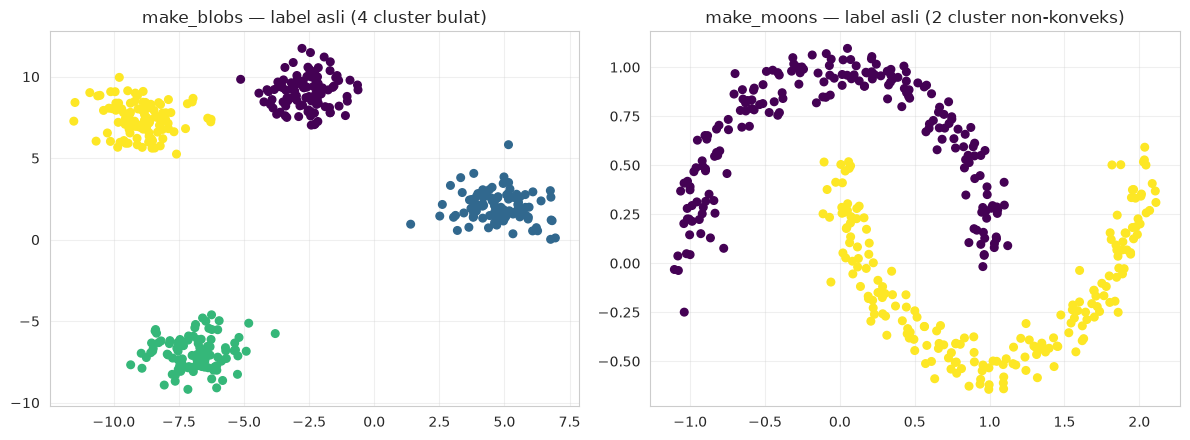

In [2]:
# ============================================
# Buat dataset kontrol (random_state=42)
# ============================================
X_blobs, y_blobs = make_blobs(n_samples=400, centers=4, cluster_std=1.0,
                              random_state=42)
X_moons, y_moons = make_moons(n_samples=400, noise=0.07, random_state=42)

# Scaling sama seperti pipeline PBL
Xb = StandardScaler().fit_transform(X_blobs)
Xm = StandardScaler().fit_transform(X_moons)
Xb_cos = normalize(Xb, norm='l2')
Xm_cos = normalize(Xm, norm='l2')

print(f"make_blobs : {Xb.shape}, label asli = {len(set(y_blobs))} cluster (bulat)")
print(f"make_moons : {Xm.shape}, label asli = {len(set(y_moons))} cluster (non-konveks)")

# Visualisasi ground truth
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, cmap='viridis', s=30)
axes[0].set_title('make_blobs — label asli (4 cluster bulat)')
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis', s=30)
axes[1].set_title('make_moons — label asli (2 cluster non-konveks)')
for ax in axes: ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [3]:
# ============================================
# Algoritma pembantu (sama seperti notebook PBL)
# ============================================
def kmedians(X, k, random_state=42, max_iter=100):
    rng = np.random.RandomState(random_state)
    medians = X[rng.choice(len(X), k, replace=False)].copy()
    for it in range(max_iter):
        lab = manhattan_distances(X, medians).argmin(axis=1)
        new = np.array([np.median(X[lab == j], axis=0) if (lab == j).any()
                        else medians[j] for j in range(k)])
        if np.allclose(new, medians): break
        medians = new
    return lab

def spherical_kmeans(X, k, random_state=42, max_iter=100):
    rng = np.random.RandomState(random_state)
    centroids = normalize(X[rng.choice(len(X), k, replace=False)], norm='l2')
    for it in range(max_iter):
        lab = (X @ centroids.T).argmax(axis=1)
        new = np.array([normalize(X[lab == j].mean(axis=0).reshape(1, -1),
                                  norm='l2')[0] if (lab == j).any()
                        else centroids[j] for j in range(k)])
        if np.allclose(new, centroids): break
        centroids = new
    return lab

print("Fungsi K-Medians & Spherical K-Means siap.")

Fungsi K-Medians & Spherical K-Means siap.


In [4]:
def evaluate(method, metric, X_std, X_cos, y_true, k):
    """
    Jalankan clustering pada dataset kontrol dan hitung SEMUA metrik evaluasi
    termasuk ARI & NMI (label ground truth tersedia).
    method: 'K-Means', 'DBSCAN', 'Hierarchical' | metric: euclidean/manhattan/cosine
    """
    X = X_cos if metric == 'cosine' else X_std
    tracemalloc.start(); start = time.time()

    if method == 'K-Means':
        if metric == 'euclidean':
            labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        elif metric == 'manhattan':
            labels = kmedians(X, k)
        else:
            labels = spherical_kmeans(X, k)
    elif method == 'DBSCAN':
        # eps kecil untuk data kontrol yang rapat; min_samples=4 (konsisten)
        eps_map = {'euclidean': 0.5, 'manhattan': 1.0, 'cosine': 0.05}
        labels = DBSCAN(eps=eps_map[metric], min_samples=4, metric=metric,
                        algorithm='brute' if metric == 'cosine' else 'auto').fit_predict(X)
    else:  # Hierarchical
        labels = AgglomerativeClustering(n_clusters=k, metric=metric,
                                         linkage='average').fit_predict(X)

    exec_time = time.time() - start
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    mask = labels != -1
    Xsil = X if mask.all() else X[mask]
    lsil = labels if mask.all() else labels[mask]
    sil = silhouette_score(Xsil, lsil, metric=metric) if len(set(lsil)) > 1 else None
    dbi = davies_bouldin_score(X_std[mask] if not mask.all() else X_std, lsil) if len(set(lsil)) > 1 else None
    ari = adjusted_rand_score(y_true, labels)
    nmi = normalized_mutual_info_score(y_true, labels)

    return {'Metode': method, 'Metric': metric.capitalize(), 'k': k,
            'Jumlah Cluster': n_clusters, '% Noise': round(n_noise/len(labels)*100, 2),
            'Silhouette': round(sil, 4) if sil is not None else None,
            'DBI': round(dbi, 4) if dbi is not None else None,
            'ARI': round(ari, 4), 'NMI': round(nmi, 4),
            'Waktu (ms)': round(exec_time*1000, 2), 'Memory (KB)': round(peak/1024, 2)}

print("Fungsi evaluate (dengan ARI & NMI) siap.")

Fungsi evaluate (dengan ARI & NMI) siap.


In [5]:
# ============================================
# make_blobs : k dikunci = 4 (jumlah cluster sebenarnya)
# ============================================
hasil_blobs = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    hasil_blobs.append(evaluate('K-Means', metric, Xb, Xb_cos, y_blobs, 4))
    hasil_blobs.append(evaluate('DBSCAN', metric, Xb, Xb_cos, y_blobs, 4))
    hasil_blobs.append(evaluate('Hierarchical', metric, Xb, Xb_cos, y_blobs, 4))

df_blobs = pd.DataFrame(hasil_blobs)
print("="*80); print("HASIL DATASET KONTROL: make_blobs (k=4)"); print("="*80)
df_blobs

HASIL DATASET KONTROL: make_blobs (k=4)


,Metode,Metric,k,Jumlah Cluster,% Noise,Silhouette,DBI,ARI,NMI,Waktu (ms),Memory (KB)
0,K-Means,Euclidean,4,4,0.0,0.7999,0.2780,1.0000,1.0000,84.25,822.31
1,DBSCAN,Euclidean,4,3,0.0,0.7432,0.3696,0.7127,0.8571,5.14,126.37
2,Hierarchical,Euclidean,4,4,0.0,0.7972,0.2801,0.9933,0.9899,7.12,715.45
3,K-Means,Manhattan,4,4,0.0,0.7921,0.2780,1.0000,1.0000,3.46,23.56
4,DBSCAN,Manhattan,4,3,0.0,0.7536,0.3696,0.7127,0.8571,4.68,116.99
5,Hierarchical,Manhattan,4,4,0.0,0.7891,0.2801,0.9933,0.9899,4.41,705.32
6,K-Means,Cosine,4,4,0.0,0.9721,0.2780,1.0000,1.0000,6.02,23.93
7,DBSCAN,Cosine,4,4,0.0,0.9721,0.2780,1.0000,1.0000,6.27,3133.72
8,Hierarchical,Cosine,4,4,0.0,0.9721,0.2780,1.0000,1.0000,4.32,705.32


In [6]:
# ============================================
# make_moons : k dikunci = 2 (jumlah cluster sebenarnya)
# ============================================
hasil_moons = []
for metric in ['euclidean', 'manhattan', 'cosine']:
    hasil_moons.append(evaluate('K-Means', metric, Xm, Xm_cos, y_moons, 2))
    hasil_moons.append(evaluate('DBSCAN', metric, Xm, Xm_cos, y_moons, 2))
    hasil_moons.append(evaluate('Hierarchical', metric, Xm, Xm_cos, y_moons, 2))

df_moons = pd.DataFrame(hasil_moons)
print("="*80); print("HASIL DATASET KONTROL: make_moons (k=2)"); print("="*80)
df_moons

HASIL DATASET KONTROL: make_moons (k=2)


,Metode,Metric,k,Jumlah Cluster,% Noise,Silhouette,DBI,ARI,NMI,Waktu (ms),Memory (KB)
0,K-Means,Euclidean,2,2,0.0,0.4924,0.8171,0.4748,0.3778,13.53,46.56
1,DBSCAN,Euclidean,2,2,0.0,0.3775,1.0430,1.0000,1.0000,5.27,117.45
2,Hierarchical,Euclidean,2,2,0.0,0.4489,0.8706,0.6472,0.6251,4.65,705.28
3,K-Means,Manhattan,2,2,0.0,0.4860,0.8239,0.4543,0.3598,6.76,21.46
4,DBSCAN,Manhattan,2,1,0.0,NaN,NaN,0.0000,0.0000,5.62,116.94
5,Hierarchical,Manhattan,2,2,0.0,0.4272,0.8601,0.4749,0.5006,4.13,705.25
6,K-Means,Cosine,2,2,0.0,0.7080,0.8171,0.4748,0.3778,5.41,17.46
7,DBSCAN,Cosine,2,1,0.0,NaN,NaN,0.0000,0.0000,6.29,3132.99
8,Hierarchical,Cosine,2,2,0.0,0.6995,0.8198,0.5172,0.4173,4.12,705.23


In [7]:
df_blobs.to_csv('hasil_kontrol_blobs.csv', index=False)
df_moons.to_csv('hasil_kontrol_moons.csv', index=False)
print("Disimpan: hasil_kontrol_blobs.csv & hasil_kontrol_moons.csv")

print("\n>> Verifikasi teori:")
print("   - K-Means Euclidean ARI tinggi di blobs (cluster bulat)  :",
      df_blobs[(df_blobs['Metode']=='K-Means') & (df_blobs['Metric']=='Euclidean')]['ARI'].values)
print("   - DBSCAN ARI tinggi di moons (non-konveks)               :",
      df_moons[df_moons['Metode']=='DBSCAN']['ARI'].values)

Disimpan: hasil_kontrol_blobs.csv & hasil_kontrol_moons.csv

>> Verifikasi teori:
   - K-Means Euclidean ARI tinggi di blobs (cluster bulat)  : [1.]
   - DBSCAN ARI tinggi di moons (non-konveks)               : [1. 0. 0.]
